In [1]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np
import matplotlib.pyplot as plt

### Objetivo

Implementar un agente de RL que aprenda a invertir en un entorno simulado con un único activo.

### Definición del entorno

El **estado** (observación) es una tupla de la forma ``(tendencia, posición)`` en la que:

- ``tendencia`` es la tendencia del precio, calculada a partir de las últimas 6 observaciones.

- ``posición`` es $1$ si el agente posee el activo y $0$ si no lo posee.

En cada momento, las **acciones** son:

- $0$ = vender

- $1$ = mantener

- $2$ = comprar

Obviamente, la acción *vender* sólo tendrá efecto si el agente es poseedor del activo, y la acción *comprar* sólo tendrá efecto cuando el agente no posee el activo.


In [2]:
class SimpleTradingEnv(gym.Env):
    metadata = {"render_modes": ["human"]}

    def __init__(self, prices):
        super(SimpleTradingEnv, self).__init__()
        self.prices = prices
        self.max_steps = len(prices) - 1

        # Acciones: 0 = Vender, 1 = Mantener, 2 = Comprar
        self.action_space = spaces.Discrete(3)

        # Estado: [tendencia_precio (-1 a 1), posicion_actual (0 o 1)]
        self.observation_space = spaces.Box(
            low=np.array([-1.0, 0], dtype=np.float32),
            high=np.array([1.0, 1], dtype=np.float32),
            dtype=np.float32
        )

    def reset(self, seed=None):
        super().reset(seed=seed)
        self.current_step = 5  # Empezar con suficiente historia para la media
        self.position = 0      # 0: sin activo, 1: con activo

        # Gestión del capital
        self.initial_balance = 1000.0
        self.balance = self.initial_balance  # Valor total del portafolio (Efectivo + Activos)
        self.cash = self.initial_balance     # Dinero en efectivo disponible
        self.shares = 0.0                    # Cantidad de acciones poseídas

        return self._get_obs(), {}

    def _get_obs(self):
        # Calcular tendencia simple basada en los últimos 5 pasos
        window = self.prices[self.current_step - 5 : self.current_step + 1]
        trend = (window[-1] - np.mean(window)) / np.mean(window)
        return np.array([np.clip(trend, -1.0, 1.0), self.position], dtype=np.float32)

    def step(self, action):
        prev_price = self.prices[self.current_step]
        self.current_step += 1
        curr_price = self.prices[self.current_step]

        reward = 0.0
        cost_rate = 0.001  # Comisión del 0.1% por transacción

        # 1. Ejecutar acciones y actualizar efectivo/acciones
        if action == 2 and self.position == 0:  # Comprar
            # Usar todo el efectivo disponible para comprar acciones al precio anterior
            commission = self.cash * cost_rate
            effective_cash = self.cash - commission
            self.shares = effective_cash / prev_price
            self.cash = 0.0
            self.position = 1
            reward -= cost_rate

        elif action == 0 and self.position == 1:  # Vender
            # Vender todas las acciones al precio anterior
            sale_value = self.shares * prev_price
            commission = sale_value * cost_rate
            self.cash = sale_value - commission
            self.shares = 0.0
            self.position = 0
            reward -= cost_rate

        # 2. Calcular recompensa por variación del precio si mantiene la posición
        if self.position == 1:
            price_change = (curr_price - prev_price) / prev_price
            reward += price_change

        # 3. Actualizar el balance total (Net Worth) al finalizar el paso
        if self.position == 1:
            self.balance = self.cash + (self.shares * curr_price)
        else:
            self.balance = self.cash

        terminated = self.current_step >= self.max_steps
        truncated = False

        # Opcional: puedes pasar el balance actual en el diccionario de info
        info = {"balance": self.balance}

        return self._get_obs(), reward, terminated, truncated, info

### Funciones para generar precios

Se proponen cuatro funciones generadoras de precios. Las pruebas deben hacerse al menos con estas cuatro funciones. Si se desea, pueden añadirse otras funciones de diferentes características, o incluso probar con alguna serie de precios real.

#### 1. Tendencia suave + componente cíclica

In [3]:
def generar_precios(n_steps=1000):
    # Combinar una tendencia suave (drift) + componente cíclico + ruido
    t = np.linspace(0, 50, n_steps)
    drift = 0.0005 * t
    ciclo = np.sin(t) * 0.05
    ruido = np.random.normal(0, 0.1, n_steps)

    # Precio base acumulado
    retornos = drift + ciclo + ruido
    precios = 100 * np.cumprod(1 + retornos)
    return precios

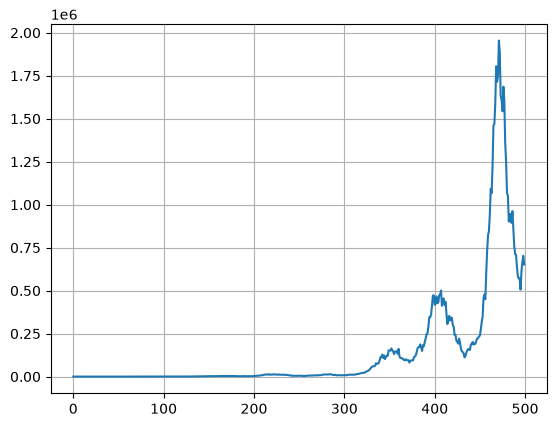

In [4]:
precios = generar_precios(n_steps=500)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

#### 2. Movimiento browniano

In [5]:
def generar_precios_browniano(n_steps=1000, start_price=100.0, mu=0.0001, sigma=0.02):
    """
    Genera precios usando Movimiento Browniano Geométrico.
    - mu: Tendencia o deriva esperada (drift).
    - sigma: Volatilidad (desviación estándar de los retornos).
    """
    dt = 1.0
    # Retornos logarítmicos distribuidos normalmente
    retornos = np.random.normal((mu - 0.5 * sigma**2) * dt, sigma * np.sqrt(dt), n_steps)
    precios = start_price * np.cumprod(np.exp(retornos))
    return precios

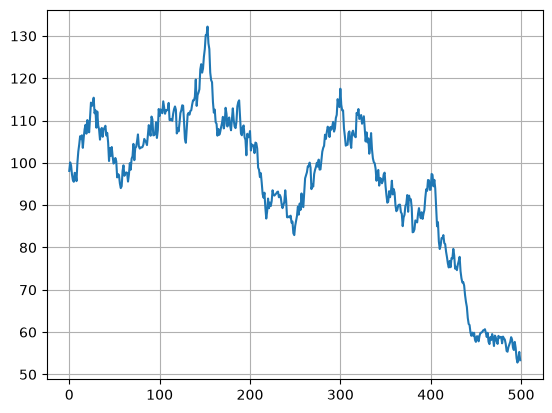

In [6]:
precios = generar_precios_browniano(n_steps=500)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

#### 3. Reversión a la media

In [7]:
def generar_precios_reversion_media(n_steps=1000, start_price=100.0, mean_price=100.0, kappa=0.05, volatility=0.02):
    """
    Genera precios que tienden a revertir hacia un valor medio.
    - mean_price: El precio objetivo o de equilibrio.
    - kappa: Velocidad de reversión (cuánto más alto, más rápido vuelve al valor medio).
    - volatility: Magnitud del ruido aleatorio añadido en cada paso.
    """
    precios = np.zeros(n_steps)
    precios[0] = start_price

    for t in range(1, n_steps):
        # Fuerza de atracción hacia la media + ruido aleatorio
        delta = kappa * (mean_price - precios[t-1]) + np.random.normal(0, volatility * mean_price)
        precios[t] = precios[t-1] + delta

        # Evitar precios negativos o cero por seguridad
        precios[t] = max(precios[t], 0.1)

    return precios

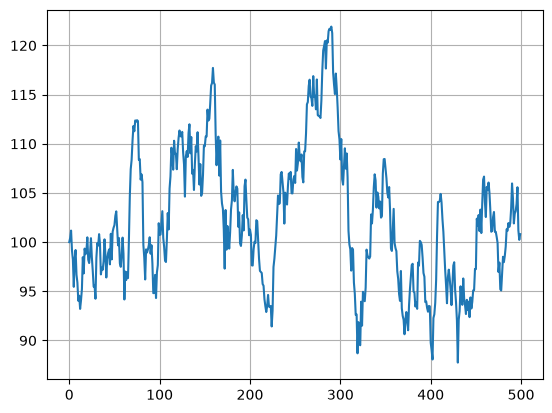

In [8]:
precios = generar_precios_reversion_media(n_steps=500)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

#### 4. Alternancia entre regímenes alcistas y bajistas

In [9]:
def generar_precios_regimenes(n_steps=1000, start_price=100.0):
    """
    Genera precios alternando entre regímenes alcistas y bajistas de forma estocástica.
    """
    precios = np.zeros(n_steps)
    precios[0] = start_price

    # Estado inicial: 0 = Alcista, 1 = Bajista
    estado = 0

    retornos = []
    for _ in range(n_steps):
        # Probabilidad de cambiar de régimen en cada paso
        if np.random.rand() < 0.02:
            estado = 1 - estado

        if estado == 0:  # Régimen alcista
            ret = np.random.normal(0.001, 0.01)
        else:            # Régimen bajista (caídas con más ruido)
            ret = np.random.normal(-0.0015, 0.025)

        retornos.append(ret)

    retornos = np.array(retornos)
    precios = start_price * np.cumprod(1 + retornos)

    # Asegurar que no haya valores negativos
    precios = np.maximum(precios, 0.1)
    return precios

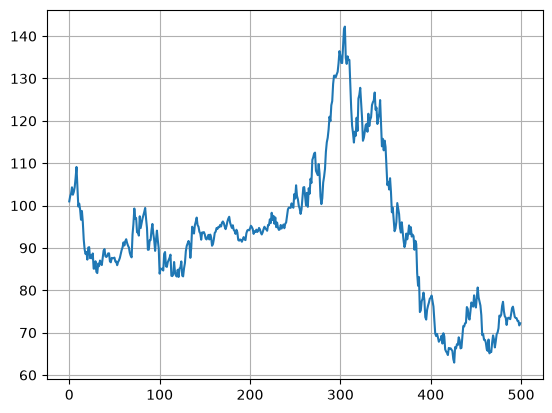

In [10]:
precios = generar_precios_regimenes(n_steps=500)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

### Agente aleatorio

Como línea base, se proporciona un agente aleatorio que en cada instante selecciona la acción al azar. A continuación se compara su rendimiento en un episodio con la estrategia *buy & hold*.

In [11]:
n_steps = 500
prices = generar_precios(n_steps)
env = SimpleTradingEnv(prices)

obs, info = env.reset()
terminated = False
step_count = 0

balances = [env.balance]
actions_taken = []
positions = []

while not terminated:
    action = env.action_space.sample()
    positions.append(env.position)
    actions_taken.append(action)

    obs, reward, terminated, truncated, info = env.step(action)
    balances.append(env.balance)

positions = np.array(positions)
actions_taken = np.array(actions_taken)
valid_prices = prices[5:-1]

In [12]:
prices_on = valid_prices.copy()
prices_on[positions==0] = np.nan
prices_off = valid_prices.copy()
prices_off[positions==1] = np.nan

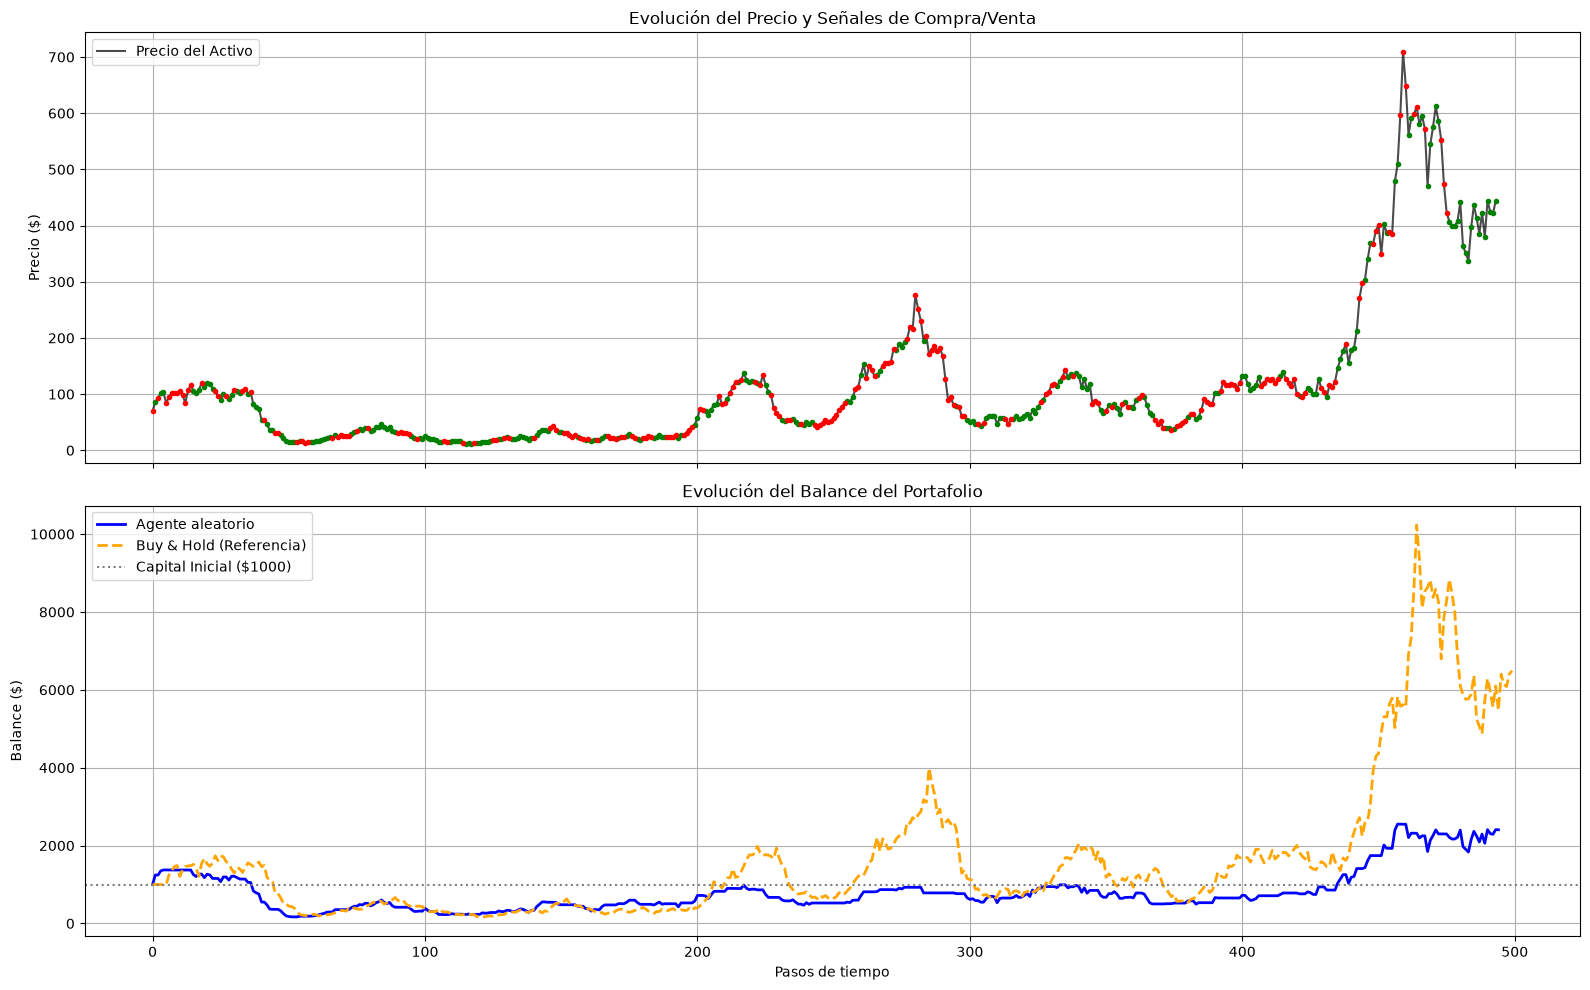

In [13]:
# --- Estrategia Buy & Hold para el panel de balance ---
bh_initial_cash = 1000.0
bh_start_price = prices[5]
bh_shares = (bh_initial_cash * 0.999) / bh_start_price
bh_balances = [bh_initial_cash if i < 5 else bh_shares * p for i, p in enumerate(prices)]

# --- Crear la figura con 2 Subgráficas ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

# PANEL 1: Evolución del precio y señales de Trading
ax1.plot(valid_prices, label="Precio del Activo", color="black", alpha=0.7, linewidth=1.5)
ax1.plot(prices_on, 'g.')
ax1.plot(prices_off, 'r.')
ax1.set_title("Evolución del Precio y Señales de Compra/Venta")
ax1.set_ylabel("Precio ($)")
ax1.legend(loc="upper left")
ax1.grid(True)

# PANEL 2: Evolución del Balance (Portafolio)
ax2.plot(balances, label="Agente aleatorio", color="blue", linewidth=2)
ax2.plot(bh_balances, label="Buy & Hold (Referencia)", color="orange", linestyle="--", linewidth=2)
ax2.axhline(y=1000, color="gray", linestyle=":", label="Capital Inicial ($1000)")

ax2.set_title("Evolución del Balance del Portafolio")
ax2.set_xlabel("Pasos de tiempo")
ax2.set_ylabel("Balance ($)")
ax2.legend(loc="upper left")
ax2.grid(True)

plt.tight_layout()
plt.show()

### Ejercicios y notas sobre la implementación

1. Implementar los algoritmos vistos en clase y probarlos con distintas funciones de generación de los precios. Deben implementarse al menos los algoritmos *Q-Learning* y *Sarsa*, usando al menos las cuatro funciones de generación de precio propuestas.

   - Cada agente debe entrenarse con varios (muchos) episodios, y cada episodio debería usar una serie de precios distinta, aunque todas deberían ser generadas por la misma función. De este modo el agente puede aprender las regularidades de cada tipo de *mercado* sin repetir siempre los mismos datos para entrenar.

   - Para evaluar los agentes entrenados, se deberían usar datos de *test*, series de precios nuevas generadas a partir de la misma función usada durante el entrenamiento. Los resultados deberían promediarse sobre varias series de test.

2. Analizar las soluciones obtenidas para cada función de generación de precios, y compararlas con el agente aleatorio y con la estrategia *buy & hold*. Razonar si la estrategia encontrada en cada caso es la esperada.

3. Ajustar de manera adecuada los hiperparámetros de cada modelo, en particular el factor de aprendizaje $\alpha$, la tasa de exploración $\epsilon$ (probablemente con decaimiento temporal), el factor de descuento $\gamma$, y el número de episodios de entrenamiento.

4. Comparar en una tabla las soluciones obtenidas con cada algoritmo, incluyendo los *baselines*, sobre cada problema (función generadora de precios). Analizar al menos el rendimiento y el tiempo de convergencia.



### Entrega

Debe entregarse un documento en pdf de un **máximo de dos páginas** con un resumen de las pruebas realizadas, los resultados obtenidos y las conclusiones extraidas.

Las entregas se harán por grupos. Cada grupo de TFM realizará una entrega.

La fecha tope para la entrega es el **29/10/2026**, a las **23:59**.

**Importante:** Una primera versión del documento se deberá entregar por e-mail a luis.lago@uam.es antes de la clase del jueves 29 de octubre. En dicha clase cada grupo presentará su trabajo y lo discutirá con el profesor durante un máximo de 15 minutos. Los comentarios recibidos pueden usarse para mejorar el documento para la entrega final.

De cara a organizar las presentaciones, un representante de cada grupo debe enviar un e-mail al profesor antes del martes 27 de octubre. Ese mismo día os indicaré, mediante mensaje a los representantes, el orden de presentación.

### Evaluación

La realización de los ejercicios y pruebas propuestos garantiza el aprobado en la práctica (50%). El otro 50% se obtendrá valorando la realización de pruebas que vayan más allá de los mínimos planteados (10%), la calidad de presentación de los resultados (20%), la justificación de las decisiones de diseño tomadas (10%) y el análisis crítico de las soluciones obtenidas (10%).

# SARSA

Implementamos SARSA tabular sobre el entorno del profesor. Seguimos el mismo proceso que Higinio con Q-learning: discretizar, entrenar, seleccionar hiperparámetros, decidir la duración y evaluar sobre series nuevas.

Ejecuta las celdas en orden. La ejecución completa incluye ocho configuraciones por mercado y el estudio de duración, por lo que puede tardar varias decenas de minutos. El entorno, los generadores y la discretización se mantienen para facilitar la comparación entre algoritmos.

In [14]:
from time import perf_counter
from itertools import product
from matplotlib.ticker import PercentFormatter
from IPython.display import Markdown, display

## 1. Discretización del espacio de estados

La observación contiene **tendencia y posición**. Usamos las mismas 13 fronteras que Higinio: generan 14 intervalos de tendencia, más estrechos cerca de cero. Combinados con las dos posiciones posibles producen **28 estados**.

La tabla `Q[tendencia, posición, acción]` tiene forma **14 × 2 × 3** y empieza en cero. Las acciones son `0 = vender`, `1 = mantener` y `2 = comprar`. `np.digitize` asigna cada tendencia a su intervalo; un valor situado en una frontera entra en el intervalo de su derecha.

In [15]:
limites_tendencia = np.array(
    [-0.10, -0.05, -0.03, -0.02, -0.01, -0.005,
     0.0, 0.005, 0.01, 0.02, 0.03, 0.05, 0.10], dtype=np.float32
)

def discretizar(observacion):
    """Convierte la observación en el estado (intervalo de tendencia, posición)."""
    tendencia, posicion = observacion
    return int(np.digitize(tendencia, limites_tendencia)), int(posicion)

## 2. Entrenamiento con SARSA

La política **ε-greedy** elige una acción al azar con probabilidad ε y una de las acciones con mayor Q en el resto de los casos. Los empates se resuelven al azar para no favorecer siempre la primera acción.

SARSA utiliza la transición **estado, acción, recompensa, siguiente estado y siguiente acción**:

$$
Q(s,a) \leftarrow Q(s,a) + \alpha\left[r + \gamma Q(s',a') - Q(s,a)\right].
$$

α controla cuánto corregimos la estimación y γ el peso del valor futuro. **Q-learning utiliza el máximo Q del siguiente estado; SARSA utiliza el Q de la acción que ha elegido y ejecutará.** Por eso seleccionamos `siguiente_accion` antes de actualizar y la conservamos para el siguiente paso. Al terminar el episodio, el objetivo es únicamente la recompensa.

Cada episodio utiliza una serie nueva del mismo generador. Se reinicia el capital, pero se conserva Q. ε disminuye después de cada episodio hasta su mínimo. El argumento opcional `controles` guarda copias de Q para estudiar después la duración, sin alterar el aprendizaje.

In [16]:
def elegir_accion(q_table, estado, epsilon, rng):
    """Elige una acción con epsilon-greedy y desempata al azar."""
    if rng.random() < epsilon:
        return int(rng.integers(3))
    valores = q_table[estado]
    mejores = np.flatnonzero(valores == valores.max())
    return int(rng.choice(mejores))

In [17]:
def entrenar_sarsa(generador, n_episodes=1000, n_steps=500,
                   alpha=0.1, gamma=0.99, epsilon=1.0,
                   epsilon_decay=0.995, min_epsilon=0.05, seed=42, controles=()):
    """Entrena SARSA y devuelve Q, sus copias y el retorno de cada episodio."""
    np.random.seed(seed)
    rng = np.random.default_rng(seed)
    q_table = np.zeros((len(limites_tendencia) + 1, 2, 3), dtype=np.float32)
    copias = {}
    retornos = []

    for episodio in range(n_episodes):
        env = SimpleTradingEnv(generador(n_steps=n_steps))
        observacion, _ = env.reset()
        estado = discretizar(observacion)
        accion = elegir_accion(q_table, estado, epsilon, rng)
        fin = False

        while not fin:
            observacion, recompensa, terminado, truncado, _ = env.step(accion)
            fin = terminado or truncado
            siguiente_estado = discretizar(observacion)
            if fin:
                objetivo = recompensa
            else:
                siguiente_accion = elegir_accion(q_table, siguiente_estado, epsilon, rng)
                objetivo = recompensa + gamma * q_table[(*siguiente_estado, siguiente_accion)]

            indice = (*estado, accion)
            q_table[indice] += alpha * (objetivo - q_table[indice])
            if not fin:
                estado, accion = siguiente_estado, siguiente_accion

        retornos.append(env.balance / env.initial_balance - 1)
        if episodio + 1 in controles:
            copias[episodio + 1] = q_table.copy()
        epsilon = max(min_epsilon, epsilon * epsilon_decay)

    return q_table, copias, np.asarray(retornos)

## 3. Selección de hiperparámetros

### Validación fija y evaluación sin aprendizaje

Como Higinio, usamos **50 series de validación por mercado**, con semillas 2026 a 2029. Todas las configuraciones se evalúan sobre las mismas series, con ε = 0 y sin modificar Q.

Comparamos el **retorno de la cartera**: `balance_final / balance_inicial - 1`. No es la suma de recompensas, porque el patrimonio se capitaliza. El entorno parte de 1.000 unidades, cobra un 0,1 % por operación efectiva y valora la posición final sin forzar una venta.

La misma función evalúa SARSA y los baselines: aleatorio, buy & hold y efectivo. Solo contamos una operación cuando cambia la posición. La matriz resultante tiene una fila por tabla Q y una columna por serie de precios.

In [18]:
generadores = {
    "Tendencia suave + ciclo": generar_precios,
    "Movimiento browniano": generar_precios_browniano,
    "Reversión a la media": generar_precios_reversion_media,
    "Cambios de régimen": generar_precios_regimenes,
}

def generar_series(generador, cantidad, seed):
    """Genera un banco reproducible de series de 500 precios."""
    np.random.seed(seed)
    return [generador(n_steps=500) for _ in range(cantidad)]

In [19]:
def evaluar_tablas(tablas, series, estrategia="SARSA", seed=30_000):
    """Evalúa tablas o baselines sobre las mismas series, sin aprender."""
    retornos = np.zeros((len(tablas), len(series)))
    operaciones = np.zeros_like(retornos)

    for fila, tabla in enumerate(tablas):
        for columna, precios in enumerate(series):
            env = SimpleTradingEnv(precios)
            observacion, _ = env.reset()
            rng = np.random.default_rng(seed + columna)
            fin = False
            while not fin:
                if estrategia == "SARSA":
                    accion = elegir_accion(tabla, discretizar(observacion), 0, rng)
                elif estrategia == "Aleatorio":
                    accion = int(rng.integers(3))
                elif estrategia == "Buy & hold":
                    accion = 2 if env.position == 0 else 1
                elif estrategia == "Efectivo":
                    accion = 1
                else:
                    raise ValueError(f"Estrategia desconocida: {estrategia}")

                posicion_anterior = env.position
                observacion, _, terminado, truncado, _ = env.step(accion)
                fin = terminado or truncado
                operaciones[fila, columna] += int(env.position != posicion_anterior)

            retornos[fila, columna] = env.balance / env.initial_balance - 1

    return {"retornos": retornos, "operaciones": operaciones}

### Rejilla y calendario de exploración

Probamos **ocho configuraciones**: α ∈ {0,10; 0,05}, ε mínimo ∈ {0,05; 0,01} y fracción de descenso ∈ {0,80; 0,25}. Mantenemos γ = 0,99, ε inicial = 1 y 1.000 episodios de 500 precios. La búsqueda se centra en α y exploración; es más pequeña que las 48 combinaciones de Higinio.

Para alcanzar ε mínimo después de $N$ reducciones, calculamos:

$$
\text{epsilon\_decay} = (\epsilon_{min}/\epsilon_0)^{1/N},
\qquad N = \operatorname{round}(\text{episodios} \times \text{fracción}).
$$

Una fracción de 0,25 significa 250 reducciones. Después se mantiene ε mínimo: el agente sigue explorando. Al cambiar el mínimo también cambia la pendiente del descenso.

Entrenamos cada configuración con las semillas **42, 43 y 44**. Elegimos una configuración por mercado por su mayor retorno medio de validación sobre las tres semillas. Un empate exacto conserva el orden de la rejilla. La desviación entre semillas permite observar si la media depende mucho de un agente.

El ranking muestra las ocho configuraciones de cada mercado, ordenadas por retorno medio; **la primera es la elegida**. `C1`–`C8` identifican el orden original de la rejilla. Los tiempos de entrenamiento suman las tres semillas y los de validación incluyen sus evaluaciones. Se miden en esta ejecución y dependen del equipo.

In [20]:
parametros_base = {
    "n_episodes": 1000, "n_steps": 500,
    "alpha": 0.1, "gamma": 0.99, "epsilon": 1.0,
    "min_epsilon": 0.05, "epsilon_decay": 0.05 ** (1 / 800),
}
semillas_rejilla = [42, 43, 44]
configuraciones = []
for alpha, minimo, fraccion in product([0.1, 0.05], [0.05, 0.01], [0.80, 0.25]):
    parametros = dict(parametros_base)
    parametros.update(alpha=alpha, min_epsilon=minimo,
                      epsilon_decay=minimo ** (1 / round(1000 * fraccion)))
    configuraciones.append({"parametros": parametros, "fraccion": fraccion})

In [21]:
resultados_rejilla = {}
mejores = {}
tiempos_ejecucion = {}
inicio_rejilla = perf_counter()
for indice, (nombre, generador) in enumerate(generadores.items()):
    series = generar_series(generador, cantidad=50, seed=2026 + indice)
    resultados_rejilla[nombre] = []
    for numero, configuracion in enumerate(configuraciones, start=1):
        inicio = perf_counter()
        tablas = []
        for semilla in semillas_rejilla:
            tabla, _, _ = entrenar_sarsa(generador, **configuracion["parametros"], seed=semilla)
            tablas.append(tabla)
        segundos_train = perf_counter() - inicio
        inicio = perf_counter()
        validacion = evaluar_tablas(tablas, series, seed=30_000 + 1000 * indice)
        segundos_validacion = perf_counter() - inicio
        resultados_rejilla[nombre].append({
            **configuracion, "numero": numero, "validacion": validacion,
            "segundos_train": segundos_train, "segundos_validacion": segundos_validacion,
        })
        print(f"{nombre} | C{numero}/8 | validación: {validacion['retornos'].mean():.4%} | "
              f"entrenamiento: {segundos_train:.1f}s | validación: {segundos_validacion:.1f}s",
              flush=True)

    mejores[nombre] = max(resultados_rejilla[nombre],
                         key=lambda r: r["validacion"]["retornos"].mean())
tiempos_ejecucion["Rejilla: entrenamiento y validación"] = perf_counter() - inicio_rejilla
print(f"Rejilla completa: {tiempos_ejecucion['Rejilla: entrenamiento y validación'] / 60:.2f} min")

Tendencia suave + ciclo | C1/8 | validación: 192229.7394% | entrenamiento: 19.8s | validación: 1.1s


Tendencia suave + ciclo | C2/8 | validación: 292318.7601% | entrenamiento: 20.9s | validación: 1.0s


Tendencia suave + ciclo | C3/8 | validación: 259844.3252% | entrenamiento: 20.8s | validación: 1.1s


Tendencia suave + ciclo | C4/8 | validación: 101020.6895% | entrenamiento: 21.6s | validación: 1.1s


Tendencia suave + ciclo | C5/8 | validación: 272359.2088% | entrenamiento: 20.2s | validación: 1.1s


...

Cambios de régimen | C5/8 | validación: 0.0000% | entrenamiento: 20.7s | validación: 1.0s


Cambios de régimen | C6/8 | validación: -2.7556% | entrenamiento: 21.6s | validación: 1.0s


Cambios de régimen | C7/8 | validación: -0.0194% | entrenamiento: 21.5s | validación: 1.1s


Cambios de régimen | C8/8 | validación: -1.8435% | entrenamiento: 21.7s | validación: 1.0s


Rejilla completa: 12.42 min


In [22]:
for nombre, resultados in resultados_rejilla.items():
    ranking = sorted(resultados, key=lambda r: r["validacion"]["retornos"].mean(), reverse=True)
    filas = [f"### {nombre}", "",
             "| Config. | α | ε mínimo | Fracción | Retorno validación | Desv. semillas | Train (s) | Val. (s) |",
             "|:--|--:|--:|--:|--:|--:|--:|--:|"]
    for puesto, resultado in enumerate(ranking):
        p = resultado["parametros"]
        retornos = resultado["validacion"]["retornos"]
        etiqueta = f"C{resultado['numero']}"
        if puesto == 0:
            etiqueta = f"**{etiqueta} (elegida)**"
        filas.append(f"| {etiqueta} | {p['alpha']:.2f} | {p['min_epsilon']:.0%} | "
                     f"{resultado['fraccion']:.0%} | {retornos.mean():.4%} | "
                     f"{retornos.mean(axis=1).std():.4%} | {resultado['segundos_train']:.1f} | "
                     f"{resultado['segundos_validacion']:.1f} |")
    display(Markdown("\n".join(filas)))

### Tendencia suave + ciclo

| Config. | α | ε mínimo | Fracción | Retorno validación | Desv. semillas | Train (s) | Val. (s) |
|:--|--:|--:|--:|--:|--:|--:|--:|
| **C7 (elegida)** | 0.05 | 1% | 80% | 519915.9666% | 121629.1656% | 20.9 | 1.1 |
| C6 | 0.05 | 5% | 25% | 417274.2689% | 60807.2544% | 21.3 | 1.1 |
| C2 | 0.10 | 5% | 25% | 292318.7601% | 276535.2399% | 20.9 | 1.0 |
| C5 | 0.05 | 5% | 80% | 272359.2088% | 123633.7722% | 20.2 | 1.1 |
| C3 | 0.10 | 1% | 80% | 259844.3252% | 138756.4986% | 20.8 | 1.1 |
| C8 | 0.05 | 1% | 25% | 258879.7199% | 185677.5485% | 21.6 | 1.1 |
| C1 | 0.10 | 5% | 80% | 192229.7394% | 142303.4482% | 19.8 | 1.1 |
| C4 | 0.10 | 1% | 25% | 101020.6895% | 95442.8932% | 21.6 | 1.1 |

### Movimiento browniano

| Config. | α | ε mínimo | Fracción | Retorno validación | Desv. semillas | Train (s) | Val. (s) |
|:--|--:|--:|--:|--:|--:|--:|--:|
| **C8 (elegida)** | 0.05 | 1% | 25% | 0.0020% | 0.0028% | 21.3 | 1.1 |
| C1 | 0.10 | 5% | 80% | 0.0000% | 0.0000% | 20.1 | 1.1 |
| C3 | 0.10 | 1% | 80% | 0.0000% | 0.0000% | 20.7 | 1.1 |
| C5 | 0.05 | 5% | 80% | 0.0000% | 0.0000% | 20.1 | 1.0 |
| C7 | 0.05 | 1% | 80% | 0.0000% | 0.0000% | 20.6 | 1.1 |
| C2 | 0.10 | 5% | 25% | -0.4644% | 0.6567% | 21.1 | 1.0 |
| C6 | 0.05 | 5% | 25% | -0.4745% | 0.6711% | 21.0 | 1.1 |
| C4 | 0.10 | 1% | 25% | -3.3850% | 4.7871% | 21.5 | 1.1 |

### Reversión a la media

| Config. | α | ε mínimo | Fracción | Retorno validación | Desv. semillas | Train (s) | Val. (s) |
|:--|--:|--:|--:|--:|--:|--:|--:|
| **C5 (elegida)** | 0.05 | 5% | 80% | 1.2635% | 7.9251% | 25.9 | 1.0 |
| C7 | 0.05 | 1% | 80% | 0.1654% | 0.2340% | 25.2 | 2.6 |
| C3 | 0.10 | 1% | 80% | 0.0000% | 0.0000% | 23.1 | 1.1 |
| C6 | 0.05 | 5% | 25% | 0.0000% | 0.0000% | 27.4 | 1.2 |
| C8 | 0.05 | 1% | 25% | 0.0000% | 0.0000% | 27.8 | 1.1 |
| C2 | 0.10 | 5% | 25% | -1.7629% | 2.4932% | 22.9 | 1.1 |
| C1 | 0.10 | 5% | 80% | -2.0644% | 2.9195% | 22.3 | 1.1 |
| C4 | 0.10 | 1% | 25% | -4.9394% | 3.4944% | 24.0 | 1.2 |

### Cambios de régimen

| Config. | α | ε mínimo | Fracción | Retorno validación | Desv. semillas | Train (s) | Val. (s) |
|:--|--:|--:|--:|--:|--:|--:|--:|
| **C3 (elegida)** | 0.10 | 1% | 80% | 0.0000% | 0.0000% | 22.5 | 1.0 |
| C5 | 0.05 | 5% | 80% | 0.0000% | 0.0000% | 20.7 | 1.0 |
| C2 | 0.10 | 5% | 25% | -0.0194% | 0.0274% | 24.5 | 1.0 |
| C7 | 0.05 | 1% | 80% | -0.0194% | 0.0274% | 21.5 | 1.1 |
| C1 | 0.10 | 5% | 80% | -1.2137% | 1.7164% | 23.3 | 1.2 |
| C4 | 0.10 | 1% | 25% | -1.8435% | 2.6071% | 21.8 | 1.0 |
| C8 | 0.05 | 1% | 25% | -1.8435% | 2.6071% | 21.7 | 1.0 |
| C6 | 0.05 | 5% | 25% | -2.7556% | 3.8559% | 21.6 | 1.0 |

## 4. Curvas de aprendizaje y duración

### 4.1. Curvas de aprendizaje de las mejores configuraciones

Como en la sección 9 de Higinio, observamos cómo evoluciona el retorno **durante el entrenamiento**. Usamos las configuraciones seleccionadas y cinco semillas nuevas (501–505). Suavizamos cada curva con una **media móvil de 50 episodios**: la línea azul es la media de las cinco semillas y la banda representa ±1 desviación típica entre ellas, no un intervalo de confianza.

La línea naranja marca cuándo ε alcanza su mínimo. El gráfico muestra los primeros **1.000 episodios** e incluye acciones exploratorias: ayuda a entender el aprendizaje, pero no mide el rendimiento final de la política sin exploración. Una curva plana tampoco garantiza una política rentable.

Para comprobar después si conviene continuar, cada agente se entrena hasta 2.000 episodios y guarda Q cada 250. **Conservamos el calendario de exploración elegido para 1.000**: después continúa con ε mínimo. Evaluamos las copias al terminar sobre 200 series nuevas de validación por mercado (semillas 80.000–80.003), con ε = 0 y sin interferir en el aprendizaje.

In [23]:
semillas_finales = [501, 502, 503, 504, 505]
episodios_control = np.arange(250, 2001, 250)
estudio = {}
inicio_estudio = perf_counter()

for indice, (nombre, generador) in enumerate(generadores.items()):
    series = generar_series(generador, cantidad=200, seed=80_000 + indice)
    parametros = dict(mejores[nombre]["parametros"])
    parametros["n_episodes"] = 2000  # No recalculamos epsilon_decay.
    tablas, retornos, entrenamiento = [], [], []
    for semilla in semillas_finales:
        _, copias, historial = entrenar_sarsa(generador, **parametros, seed=semilla,
                                   controles=episodios_control)
        evaluacion = evaluar_tablas([copias[int(e)] for e in episodios_control],
                                    series, seed=100_000 + 1000 * indice)
        tablas.append(copias)
        entrenamiento.append(historial)
        retornos.append(evaluacion["retornos"])
        print(f"{nombre} | semilla {semilla}: controles evaluados", flush=True)
    estudio[nombre] = {"tablas": tablas, "retornos": np.asarray(retornos),
                       "entrenamiento": np.asarray(entrenamiento)}

tiempos_ejecucion["Duración: entrenamiento y controles"] = perf_counter() - inicio_estudio
print(f"Estudio de duración: {tiempos_ejecucion['Duración: entrenamiento y controles'] / 60:.2f} min")

Tendencia suave + ciclo | semilla 501: controles evaluados


Tendencia suave + ciclo | semilla 502: controles evaluados


Tendencia suave + ciclo | semilla 503: controles evaluados


Tendencia suave + ciclo | semilla 504: controles evaluados


Tendencia suave + ciclo | semilla 505: controles evaluados


...

Cambios de régimen | semilla 502: controles evaluados


Cambios de régimen | semilla 503: controles evaluados


Cambios de régimen | semilla 504: controles evaluados


Cambios de régimen | semilla 505: controles evaluados


Estudio de duración: 8.66 min


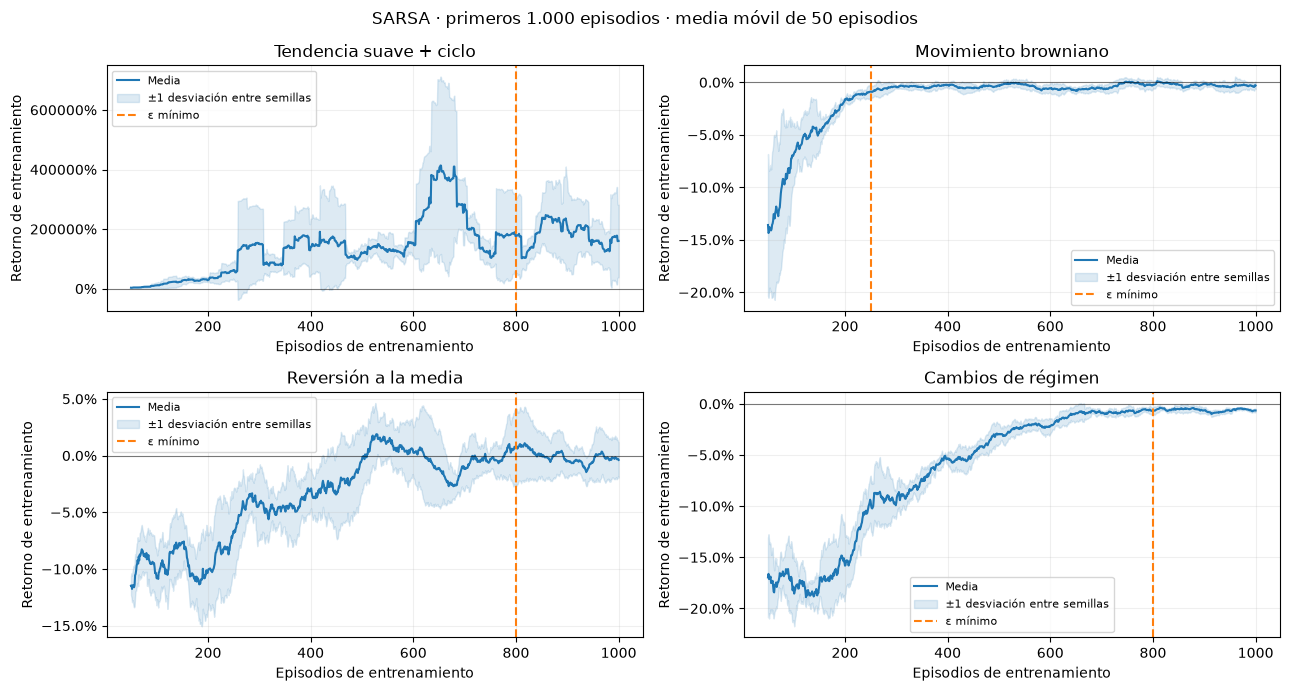

In [24]:
ventana = 50
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, (nombre, datos) in zip(axes.flat, estudio.items()):
    curvas = np.array([np.convolve(r[:1000], np.ones(ventana) / ventana, mode="valid")
                       for r in datos["entrenamiento"]])
    episodios = np.arange(ventana, 1001)
    media, desviacion = curvas.mean(axis=0), curvas.std(axis=0)
    ax.plot(episodios, media, color="tab:blue", label="Media")
    ax.fill_between(episodios, media - desviacion, media + desviacion,
                    color="tab:blue", alpha=0.15, label="±1 desviación entre semillas")
    fin_descenso = round(1000 * mejores[nombre]["fraccion"])
    ax.axvline(fin_descenso, color="tab:orange", linestyle="--", label="ε mínimo")
    ax.axhline(0, color="black", linewidth=0.8, alpha=0.5)
    ax.set(title=nombre, xlabel="Episodios de entrenamiento", ylabel="Retorno de entrenamiento")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.suptitle("SARSA · primeros 1.000 episodios · media móvil de 50 episodios")
plt.tight_layout()
plt.show()

### 4.2. Decisión sobre el número de episodios

Las curvas muestran una meseta cercana a cero en browniano y cambios de régimen, mientras que tendencia y reversión siguen oscilando.

Como en la sección 10 de Higinio, contrastamos lo que sugieren las curvas con una comparación de **1.000 frente a 2.000 episodios**. Elegimos la duración con mayor retorno medio de validación sobre las cinco semillas; en un empate conservamos 1.000. Los otros controles sirven para observar la evolución, no para elegir otra duración. El test permanece fuera de esta decisión.

**¿Cuándo consideramos estable la política?** Buscamos cambios del retorno medio de validación de como máximo 0,5 puntos porcentuales durante al menos tres intervalos y sin superar ese umbral después. En tendencia+ciclo usamos cambios relativos del 5 %, con un suelo de 0,01 en el denominador, por la escala extrema de sus retornos. Se comprueba por semilla hasta el episodio 2.000. Es estabilidad observada, no una garantía de convergencia u optimalidad.

La tabla compara ambas duraciones. En el gráfico posterior, cada punto es una evaluación sin exploración; la banda muestra el **rango entre semillas**. Así distinguimos la rentabilidad durante el entrenamiento de la rentabilidad de las políticas aprendidas.

A diferencia del experimento de Higinio, **no recalculamos `epsilon_decay` al ampliar a 2.000**. Comparamos continuar el mismo entrenamiento con detenerlo en 1.000; cambiar también la exploración respondería a otra pregunta.

In [25]:
def estimar_estabilidad(medias, episodios, relativo=False, umbral=0.005, intervalos=3):
    """Busca estabilidad en los controles observados, confirmada hasta el último."""
    cambios = np.abs(np.diff(medias))
    if relativo:
        cambios = cambios / np.maximum(np.abs(medias[:-1]), 0.01)
    for inicio in range(len(cambios) - intervalos + 1):
        if np.all(cambios[inicio:] <= umbral):
            return int(episodios[inicio + 1])
    return None


duraciones = {}
indice_1000 = int(np.flatnonzero(episodios_control == 1000)[0])
indice_2000 = int(np.flatnonzero(episodios_control == 2000)[0])
filas = ["| Mercado | Validación 1000 | Validación 2000 | Episodios elegidos | Estabilidad: semillas 501–505 |",
         "|:--|--:|--:|--:|:--|"]
for nombre, datos in estudio.items():
    medias = datos["retornos"].mean(axis=2)
    r1000, r2000 = medias[:, indice_1000].mean(), medias[:, indice_2000].mean()
    duraciones[nombre] = 2000 if r2000 > r1000 else 1000
    relativo = nombre == "Tendencia suave + ciclo"
    estables = [estimar_estabilidad(m, episodios_control, relativo=relativo,
                                   umbral=0.05 if relativo else 0.005) for m in medias]
    datos["estabilidad"] = estables
    texto_estables = ", ".join("No detectada" if e is None else str(e) for e in estables)
    filas.append(f"| {nombre} | {r1000:.4%} | {r2000:.4%} | "
                 f"{duraciones[nombre]} | {texto_estables} |")
display(Markdown("\n".join(filas)))

| Mercado | Validación 1000 | Validación 2000 | Episodios elegidos | Estabilidad: semillas 501–505 |
|:--|--:|--:|--:|:--|
| Tendencia suave + ciclo | 189692.5467% | 206958.4722% | 2000 | No detectada, No detectada, No detectada, No detectada, No detectada |
| Movimiento browniano | 0.0017% | 0.0000% | 1000 | 500, 500, 500, 500, 500 |
| Reversión a la media | -2.0044% | 1.5103% | 2000 | No detectada, No detectada, No detectada, No detectada, No detectada |
| Cambios de régimen | 0.0000% | 0.0000% | 1000 | No detectada, 500, 500, 1000, 500 |

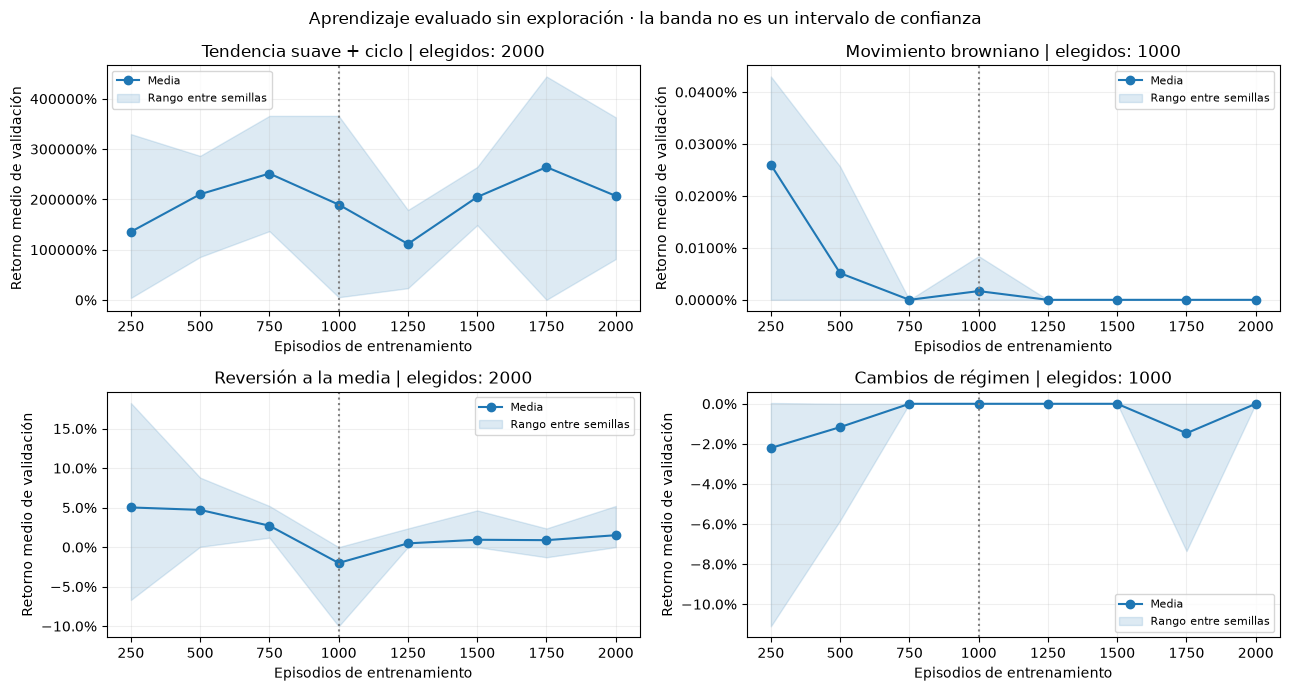

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, (nombre, datos) in zip(axes.flat, estudio.items()):
    medias = datos["retornos"].mean(axis=2)
    ax.plot(episodios_control, medias.mean(axis=0), "o-", color="tab:blue", label="Media")
    ax.fill_between(episodios_control, medias.min(axis=0), medias.max(axis=0),
                    color="tab:blue", alpha=0.15, label="Rango entre semillas")
    ax.axvline(1000, color="gray", linestyle=":")
    ax.set(title=f"{nombre} | elegidos: {duraciones[nombre]}",
           xlabel="Episodios de entrenamiento", ylabel="Retorno medio de validación")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.suptitle("Aprendizaje evaluado sin exploración · la banda no es un intervalo de confianza")
plt.tight_layout()
plt.show()

#### Conclusión sobre la duración del entrenamiento

- **Tendencia + ciclo: 2.000 episodios.** La media de validación aumenta del 189.692,55 % al 206.958,47 %. Elegimos 2.000 según el criterio fijado, aunque las oscilaciones siguen siendo grandes y ninguna semilla presenta estabilidad confirmada. No podemos concluir que el aprendizaje haya convergido.
- **Movimiento browniano: 1.000 episodios.** La validación pasa de +0,0017 % a 0 %. Entrenar más no aporta mejora; una política estable cerca de cero puede limitarse a permanecer en efectivo.
- **Reversión a la media: 2.000 episodios.** La media pasa de −2,0044 % a +1,5103 %. La ampliación mejora la validación, pero ninguna semilla cumple el criterio de estabilidad: la elección no implica robustez.
- **Cambios de régimen: 1.000 episodios.** Ambas duraciones obtienen 0 % de media. Conservamos el entrenamiento más corto; además, la caída del control 1.750 muestra que continuar no produce una mejora sostenida.

Estas decisiones utilizan exclusivamente validación. En el siguiente apartado comprobamos el resultado sobre test y las operaciones realizadas, para distinguir una política rentable de una política inactiva.

## 5. Evaluación final sobre test

Con parámetros y duración ya fijados, evaluamos sobre **200 series por mercado** (semillas 90.000–90.003), distintas de entrenamiento y validación. Comparamos SARSA, aleatorio, buy & hold y efectivo en el mismo entorno y con las mismas comisiones. El test no interviene en la selección.

SARSA utiliza las cinco tablas entrenadas; cada baseline se evalúa una vez por serie. Las **5 × 200 evaluaciones de SARSA comparten 200 mercados**: no son 1.000 mercados independientes. Mostramos media, mediana, desviación de retornos y operaciones medias. La mediana ayuda a interpretar distribuciones con resultados extremos.

Al final de la tabla se resumen los tiempos reales de la rejilla, el estudio de duración y el test. Su suma corresponde a esas tres fases; excluye la preparación inicial y el dibujo de las figuras.

In [27]:
resultados_test = {}
inicio_test = perf_counter()
for indice, (nombre, generador) in enumerate(generadores.items()):
    series = generar_series(generador, cantidad=200, seed=90_000 + indice)
    tablas = [copias[duraciones[nombre]] for copias in estudio[nombre]["tablas"]]
    resultados = {"SARSA": evaluar_tablas(tablas, series, seed=110_000 + 1000 * indice)}
    for estrategia in ["Aleatorio", "Buy & hold", "Efectivo"]:
        resultados[estrategia] = evaluar_tablas([None], series, estrategia=estrategia,
                                               seed=110_000 + 1000 * indice)
    resultados_test[nombre] = resultados
    print(f"{nombre}: test completado", flush=True)

tiempos_ejecucion["Evaluación final sobre test"] = perf_counter() - inicio_test

Tendencia suave + ciclo: test completado


Movimiento browniano: test completado


Reversión a la media: test completado


Cambios de régimen: test completado


In [28]:
filas = ["| Mercado | Estrategia | Episodios | Retorno medio | Mediana | Desv. retornos | Operaciones |",
         "|:--|:--|--:|--:|--:|--:|--:|"]
for nombre, resultados in resultados_test.items():
    for estrategia, datos in resultados.items():
        retornos = datos["retornos"]
        episodios = duraciones[nombre] if estrategia == "SARSA" else "No requiere"
        filas.append(f"| {nombre} | {estrategia} | {episodios} | {retornos.mean():.4%} | "
                     f"{np.median(retornos):.4%} | {retornos.std():.4%} | "
                     f"{datos['operaciones'].mean():.3f} |")
display(Markdown("\n".join(filas)))

filas = ["### Tiempo por fase", "", "| Fase | Minutos |", "|:--|--:|"]
for fase, segundos in tiempos_ejecucion.items():
    filas.append(f"| {fase} | {segundos / 60:.2f} |")
filas.append(f"| **Total de las tres fases** | **{sum(tiempos_ejecucion.values()) / 60:.2f}** |")
display(Markdown("\n".join(filas)))

| Mercado | Estrategia | Episodios | Retorno medio | Mediana | Desv. retornos | Operaciones |
|:--|:--|--:|--:|--:|--:|--:|
| Tendencia suave + ciclo | SARSA | 2000 | 169346.7610% | 28032.9029% | 1166806.5191% | 94.293 |
| Tendencia suave + ciclo | Aleatorio | No requiere | 2332.9138% | 366.4947% | 7195.3690% | 166.120 |
| Tendencia suave + ciclo | Buy & hold | No requiere | 23840.7641% | 3829.7092% | 58776.7601% | 1.000 |
| Tendencia suave + ciclo | Efectivo | No requiere | 0.0000% | 0.0000% | 0.0000% | 0.000 |
| Movimiento browniano | SARSA | 1000 | -0.0010% | 0.0000% | 0.0309% | 0.002 |
| Movimiento browniano | Aleatorio | No requiere | -14.2272% | -16.1694% | 27.4455% | 163.235 |
| Movimiento browniano | Buy & hold | No requiere | -1.3884% | -10.6413% | 41.1162% | 1.000 |
| Movimiento browniano | Efectivo | No requiere | 0.0000% | 0.0000% | 0.0000% | 0.000 |
| Reversión a la media | SARSA | 2000 | 1.4568% | 0.0000% | 4.6752% | 5.059 |
| Reversión a la media | Aleatorio | No requiere | -12.9108% | -14.4782% | 19.2915% | 165.115 |
| Reversión a la media | Buy & hold | No requiere | 0.3097% | 1.0143% | 7.2922% | 1.000 |
| Reversión a la media | Efectivo | No requiere | 0.0000% | 0.0000% | 0.0000% | 0.000 |
| Cambios de régimen | SARSA | 1000 | 0.0000% | 0.0000% | 0.0000% | 0.000 |
| Cambios de régimen | Aleatorio | No requiere | -19.7533% | -21.2864% | 23.9610% | 164.210 |
| Cambios de régimen | Buy & hold | No requiere | -12.7984% | -20.2572% | 38.8152% | 1.000 |
| Cambios de régimen | Efectivo | No requiere | 0.0000% | 0.0000% | 0.0000% | 0.000 |

### Tiempo por fase

| Fase | Minutos |
|:--|--:|
| Rejilla: entrenamiento y validación | 12.42 |
| Duración: entrenamiento y controles | 8.66 |
| Evaluación final sobre test | 0.59 |
| **Total de las tres fases** | **21.68** |

Cada caja representa el 50 % central de los retornos y su línea interior es la mediana. Los puntos extremos se ocultan **solo en la figura** y siguen incluidos en los cálculos. Los paneles usan escalas distintas. Una caja reducida a una línea en cero puede corresponder a muchos episodios sin operar; debe leerse junto con la tabla.

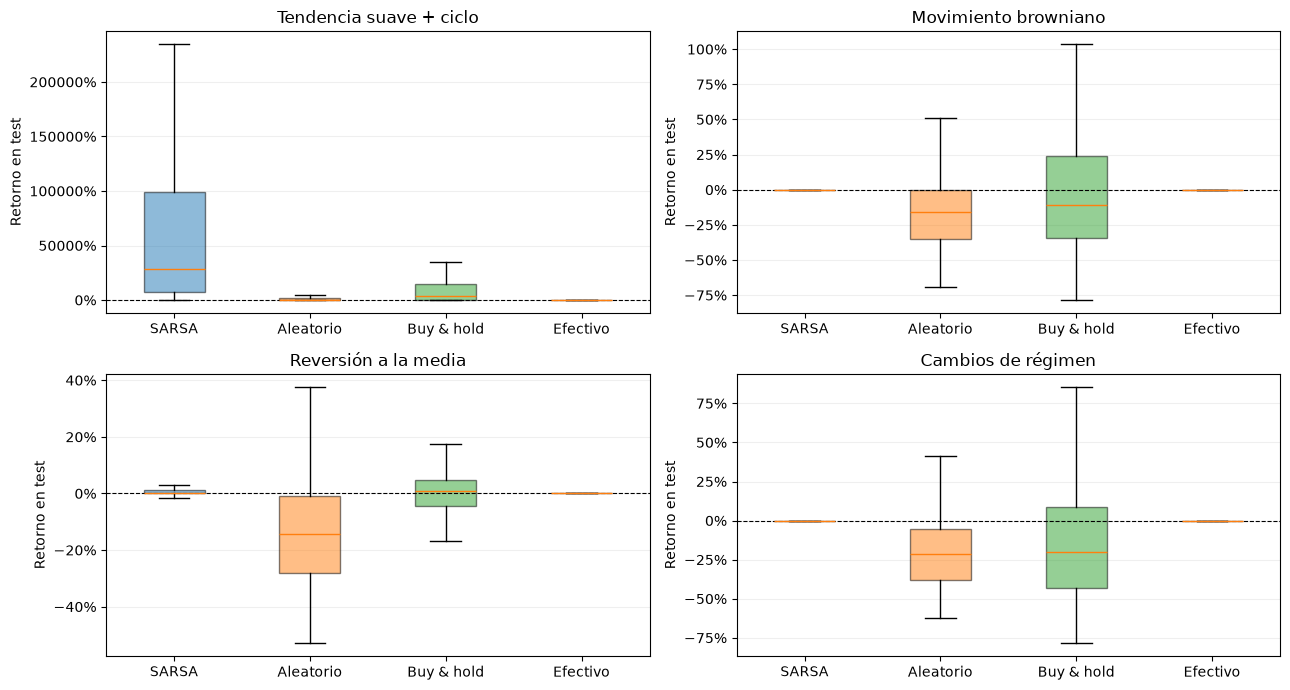

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
colores = ["tab:blue", "tab:orange", "tab:green", "silver"]
for ax, (nombre, resultados) in zip(axes.flat, resultados_test.items()):
    cajas = ax.boxplot([r["retornos"].ravel() for r in resultados.values()],
                       patch_artist=True, showfliers=False)
    ax.set_xticks(range(1, 5), list(resultados))
    for caja, color in zip(cajas["boxes"], colores):
        caja.set_facecolor(color)
        caja.set_alpha(0.5)
    ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
    ax.set(title=nombre, ylabel="Retorno en test")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

## 6. Conclusiones

**Tendencia + ciclo.** Se eligen 2.000 episodios y SARSA obtiene un retorno medio del 169.346,76 %, frente al 23.840,76 % de buy & hold. El generador capitaliza retornos por paso muy elevados, por lo que aparecen valores extremos y mucha dispersión. No se detecta estabilidad confirmada en ninguna de las cinco semillas.

**Movimiento browniano.** Se conservan 1.000 episodios. SARSA obtiene aproximadamente −0,0010 % y solo opera en una de las 1.000 evaluaciones. La estabilidad detectada corresponde a una política casi inactiva; no demuestra una ventaja predictiva frente a efectivo.

**Reversión a la media.** Ampliar a 2.000 episodios mejora la media de validación y el test obtiene +1,4568 %, frente al +0,3097 % de buy & hold. La rentabilidad procede de dos agentes; las otras tres semillas permanecen en efectivo y la mediana es cero. No se detecta estabilidad confirmada, por lo que el resultado sigue dependiendo del entrenamiento.

**Cambios de régimen.** Las dos duraciones empatan en validación y se conservan 1.000 episodios. SARSA termina en efectivo en todas las evaluaciones de test: obtiene un 0 %, frente al −12,7984 % de buy & hold. Evita pérdidas, pero no muestra capacidad para aprovechar los regímenes alcistas.

**Limitaciones.** La rejilla es pequeña, γ permanece fijo y cinco semillas no garantizan robustez. El criterio de estabilidad es heurístico y el estado resume solo tendencia local y posición. Estas conclusiones describen la ejecución guardada; si se modifican parámetros, deben revisarse. Para comparar con Q-learning en la entrega del grupo se deben usar los mismos precios de test y declarar los diferentes presupuestos de búsqueda.